In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

homes = pd.read_csv("/content/AmesHousing.csv")

print("Rows and columns:", homes.shape)
print("Column names:")
print(homes.columns.tolist())

Rows and columns: (2930, 82)
Column names:
['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Garage Qual'

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
homes.columns = (
    homes.columns
    .str.lower()
    .str.replace(r"[^a-z0-9]", "", regex=True)
)

possible_names = {
    "saleprice": ["saleprice"],
    "area": ["grlivarea", "abvgrdlivarea"],
    "neighborhood": ["neighborhood"],
    "propertytype": ["bldgtype"],
    "year": ["yrsold"],
    "month": ["mosold"]
}

found_columns = {}

for standard_name, choices in possible_names.items():
    for name in choices:
        if name in homes.columns:
            found_columns[standard_name] = name
            break

print("Columns matched:", found_columns)

required = ["saleprice", "area", "neighborhood", "propertytype", "year", "month"]
missing = [name for name in required if name not in found_columns]

if missing:
    print("Could not find these required fields:", missing)
    print("Check the printed column names and adjust possible_names.")
else:
    print("All required fields were found.")

Columns matched: {'saleprice': 'saleprice', 'area': 'grlivarea', 'neighborhood': 'neighborhood', 'propertytype': 'bldgtype', 'year': 'yrsold', 'month': 'mosold'}
All required fields were found.


In [31]:
homes = homes[
    [
        found_columns["saleprice"],
        found_columns["area"],
        found_columns["neighborhood"],
        found_columns["propertytype"],
        found_columns["year"],
        found_columns["month"]
    ]
].copy()

homes.columns = [
    "SalePrice",
    "AreaSqFt",
    "Neighborhood",
    "PropertyType",
    "YearSold",
    "MonthSold"
]

print(homes.head())

   SalePrice  AreaSqFt Neighborhood PropertyType  YearSold  MonthSold
0     215000      1656        NAmes         1Fam      2010          5
1     105000       896        NAmes         1Fam      2010          6
2     172000      1329        NAmes         1Fam      2010          6
3     244000      2110        NAmes         1Fam      2010          4
4     189900      1629      Gilbert         1Fam      2010          3


In [32]:
for column in ["SalePrice", "AreaSqFt", "YearSold", "MonthSold"]:
    homes[column] = pd.to_numeric(homes[column], errors="coerce")

homes["Neighborhood"] = homes["Neighborhood"].astype("string").str.strip().str.title()
homes["PropertyType"] = homes["PropertyType"].astype("string").str.strip().str.lower()

print("Exact duplicate rows:", homes.duplicated().sum())
homes = homes.drop_duplicates().copy()

homes = homes.dropna(
    subset=["SalePrice", "AreaSqFt", "Neighborhood", "PropertyType"]
).copy()

homes = homes[
    (homes["SalePrice"] > 0) &
    (homes["AreaSqFt"] > 0)
].copy()

homes["SaleDate"] = pd.to_datetime(
    homes["YearSold"].astype("Int64").astype(str) + "-" +
    homes["MonthSold"].astype("Int64").astype(str) + "-01",
    errors="coerce"
)

print("Rows after cleaning:", len(homes))

Exact duplicate rows: 5
Rows after cleaning: 2925


In [33]:
homes["PricePerSqFt"] = homes["SalePrice"] / homes["AreaSqFt"]

prices_per_sqft = homes["PricePerSqFt"].to_numpy()

print("25th percentile:", round(np.percentile(prices_per_sqft, 25), 2))
print("Median:", round(np.median(prices_per_sqft), 2))
print("75th percentile:", round(np.percentile(prices_per_sqft, 75), 2))

median_price = np.median(prices_per_sqft)
distance_from_median = np.abs(prices_per_sqft - median_price)
median_distance = np.median(distance_from_median)

if median_distance > 0:
    homes["OutlierFlag"] = distance_from_median / median_distance > 3.5
else:
    homes["OutlierFlag"] = False

print("Values flagged for review:", homes["OutlierFlag"].sum())

25th percentile: 100.13
Median: 120.3
75th percentile: 139.91
Values flagged for review: 104


In [34]:
homes["SizeGroup"] = pd.cut(
    homes["AreaSqFt"],
    bins=[0, 1000, 1500, 2000, 3000, float("inf")],
    labels=["Small", "Medium", "Large", "Very Large", "Extra Large"]
)

neighborhood_summary = homes.groupby("Neighborhood").agg(
    NumberOfHomes=("SalePrice", "count"),
    MedianSalePrice=("SalePrice", "median"),
    MedianPricePerSqFt=("PricePerSqFt", "median")
).sort_values("MedianPricePerSqFt", ascending=False)

print("Neighbourhood comparison:")
display(neighborhood_summary)

type_summary = homes.groupby("PropertyType").agg(
    NumberOfHomes=("SalePrice", "count"),
    MedianSalePrice=("SalePrice", "median"),
    MedianPricePerSqFt=("PricePerSqFt", "median")
).sort_values("MedianPricePerSqFt", ascending=False)

print("Property type comparison:")
display(type_summary)

size_summary = homes.groupby("SizeGroup", observed=True).agg(
    NumberOfHomes=("SalePrice", "count"),
    MedianSalePrice=("SalePrice", "median"),
    MedianPricePerSqFt=("PricePerSqFt", "median")
)

print("Size group comparison:")
display(size_summary)

year_summary = homes.groupby("YearSold").agg(
    NumberOfHomes=("SalePrice", "count"),
    MedianSalePrice=("SalePrice", "median"),
    MedianPricePerSqFt=("PricePerSqFt", "median")
)

print("Year comparison:")
display(year_summary)

Neighbourhood comparison:


,NumberOfHomes,MedianSalePrice,MedianPricePerSqFt
Neighborhood,,,
Grnhill,2,280000.0,198.656617
Greens,8,198000.0,170.269168
Nridght,166,317750.0,160.362880
Stonebr,51,319000.0,157.864524
Timber,72,232106.5,141.817341
Somerst,182,225500.0,140.531138
Blmngtn,28,191500.0,139.825328
Veenker,24,250250.0,137.719989
Collgcr,267,200000.0,135.400361


Property type comparison:


,NumberOfHomes,MedianSalePrice,MedianPricePerSqFt
PropertyType,,,
twnhse,233,180000.0,140.987285
1fam,2425,165000.0,120.694444
twnhs,101,130000.0,106.396064
2fmcon,62,122250.0,83.397723
duplex,104,136702.5,80.661681


Size group comparison:


,NumberOfHomes,MedianSalePrice,MedianPricePerSqFt
SizeGroup,,,
Small,439,117600.0,132.337796
Medium,1182,147700.0,121.003319
Large,904,195650.0,115.086135
Very Large,374,266239.5,115.295458
Extra Large,26,370050.0,111.480226


Year comparison:


,NumberOfHomes,MedianSalePrice,MedianPricePerSqFt
YearSold,,,
2006,625,159500.0,120.694444
2007,694,165125.0,122.645688
2008,621,161000.0,119.047619
2009,644,160100.0,119.599062
2010,341,155000.0,119.855596


In [35]:
comparable_groups = homes.groupby(
    ["Neighborhood", "PropertyType", "SizeGroup", "YearSold"],
    observed=True
).agg(
    NumberOfHomes=("SalePrice", "count"),
    MedianPricePerSqFt=("PricePerSqFt", "median")
).reset_index()

comparable_groups = comparable_groups[
    comparable_groups["NumberOfHomes"] >= 5
]

print("Comparable groups:")
display(comparable_groups.head(10))

homes_without_outliers = homes[~homes["OutlierFlag"]]

neighborhood_no_outliers = (
    homes_without_outliers.groupby("Neighborhood")["PricePerSqFt"]
    .median()
    .sort_values(ascending=False)
)

print("Neighbourhood medians after excluding flagged values:")
display(neighborhood_no_outliers)

Comparable groups:


,Neighborhood,PropertyType,SizeGroup,YearSold,NumberOfHomes,MedianPricePerSqFt
2,Blmngtn,twnhse,Medium,2006,6,142.492663
7,Blmngtn,twnhse,Large,2006,5,150.289017
19,Brdale,twnhs,Small,2008,5,101.823708
31,Brkside,1fam,Small,2006,6,116.932366
32,Brkside,1fam,Small,2007,7,117.664671
33,Brkside,1fam,Small,2008,10,100.656628
34,Brkside,1fam,Small,2009,6,118.262712
36,Brkside,1fam,Medium,2006,8,92.031726
37,Brkside,1fam,Medium,2007,14,103.665460
38,Brkside,1fam,Medium,2008,11,102.479339


Neighbourhood medians after excluding flagged values:


,PricePerSqFt
Neighborhood,
Grnhill,177.606178
Greens,168.026101
Nridght,154.034215
Stonebr,148.841513
Blmngtn,139.825328
Somerst,138.097797
Timber,137.107776
Veenker,136.566797
Collgcr,134.822242


In [36]:
homes.to_csv("/content/cleaned_property_table.csv", index=False)
neighborhood_summary.to_csv("/content/neighbourhood_comparison.csv")
comparable_groups.to_csv("/content/comparable_property_groups.csv", index=False)

print("Saved the cleaned table and comparison files.")


Saved the cleaned table and comparison files.


In [37]:
missing_values = homes.isna().sum().to_frame(name="MissingValues")
missing_values["PercentMissing"] = (
    missing_values["MissingValues"] / len(homes) * 100
).round(2)

display(missing_values)

,MissingValues,PercentMissing
SalePrice,0,0.0
AreaSqFt,0,0.0
Neighborhood,0,0.0
PropertyType,0,0.0
YearSold,0,0.0
MonthSold,0,0.0
SaleDate,0,0.0
PricePerSqFt,0,0.0
OutlierFlag,0,0.0
SizeGroup,0,0.0


In [38]:
neighborhood_quantiles = homes.groupby("Neighborhood").agg(
    NumberOfHomes=("PricePerSqFt", "count"),
    Price25=("PricePerSqFt", lambda values: np.percentile(values, 25)),
    MedianPrice=("PricePerSqFt", "median"),
    Price75=("PricePerSqFt", lambda values: np.percentile(values, 75))
).round(2)

display(neighborhood_quantiles.sort_values("MedianPrice", ascending=False))

,NumberOfHomes,Price25,MedianPrice,Price75
Neighborhood,,,,
Grnhill,2,188.13,198.66,209.18
Greens,8,162.54,170.27,175.33
Nridght,166,143.94,160.36,185.23
Stonebr,51,141.57,157.86,189.80
Timber,72,119.23,141.82,166.75
Somerst,182,125.13,140.53,157.39
Blmngtn,28,132.25,139.83,148.32
Veenker,24,128.89,137.72,176.84
Collgcr,267,120.59,135.40,150.09


In [39]:
segment_summary = homes.groupby(
    ["PropertyType", "SizeGroup"],
    observed=True
).agg(
    NumberOfHomes=("SalePrice", "count"),
    MedianAreaSqFt=("AreaSqFt", "median"),
    MedianSalePrice=("SalePrice", "median"),
    MedianPricePerSqFt=("PricePerSqFt", "median")
).round(2)

display(segment_summary)

NumberOfHomes  MedianAreaSqFt  MedianSalePrice  \
PropertyType SizeGroup                                                     
1fam         Small                  374           885.0         117375.0   
             Medium                 933          1264.0         147000.0   
             Large                  749          1694.0         200000.0   
             Very Large             345          2295.0         274300.0   
             Extra Large             24          3418.5         395500.0   
2fmcon       Small                   10           930.0         117000.0   
             Medium                  26          1325.5         118950.0   
             Large                   18          1799.0         136450.0   
             Very Large               7          2337.0         130000.0   
             Extra Large              1          3395.0         200000.0   
duplex       Small                    7           936.0         127500.0   
             Medium                  29          1200.0         118000.0   
             Large                   50          1728.0         135500.0   
             Very Large              18          2257.0         156650.0   
twnhs        Small                   23           987.0          96000.0   
             Medium                  56          1223.0         137700.0   
             Large                   21          1607.0         172900.0   
             Extra Large              1          3005.0         280750.0   
twnhse       Small                   25           848.0         140000.0   
             Medium                 138          1284.0         171950.0   
             Large                   66          1614.0         246495.0   
             Very Large               4          2457.0         276250.0   

                          MedianPricePerSqFt  
PropertyType SizeGroup                        
1fam         Small                    132.22  
             Medium                   120.41  
             Large                    116.57  
             Very Large               118.08  
             Extra Large              112.72  
2fmcon       Small                    124.83  
             Medium                    94.81  
             Large                     75.65  
             Very Large                55.32  
             Extra Large               58.91  
duplex       Small                    144.18  
             Medium                    89.90  
             Large                     77.47  
             Very Large                69.57  
twnhs        Small                    106.28  
             Medium                   106.70  
             Large                    107.19  
             Extra Large               93.43  
twnhse       Small                    165.09  
             Medium                   135.97  
             Large                    154.95  
             Very Large               121.73

In [40]:
all_home_medians = homes.groupby("Neighborhood")["PricePerSqFt"].median()
no_outlier_medians = homes.loc[~homes["OutlierFlag"]].groupby(
    "Neighborhood"
)["PricePerSqFt"].median()

ranking_check = pd.DataFrame({
    "MedianWithFlaggedValues": all_home_medians,
    "MedianWithoutFlaggedValues": no_outlier_medians
})

ranking_check["Difference"] = (
    ranking_check["MedianWithoutFlaggedValues"] -
    ranking_check["MedianWithFlaggedValues"]
).round(2)

display(ranking_check.sort_values("Difference", ascending=False))


,MedianWithFlaggedValues,MedianWithoutFlaggedValues,Difference
Neighborhood,,,
Oldtown,92.532468,93.468481,0.94
Idotrr,87.246180,88.092923,0.85
Edwards,102.011483,102.251023,0.24
Mitchel,134.255133,134.421134,0.17
Swisu,84.587224,84.633385,0.05
Names,119.551282,119.573912,0.02
Npkvill,111.195159,111.195159,0.00
Noridge,129.376990,129.376990,0.00
Clearcr,118.584372,118.584372,0.00


In [41]:
map_ready = homes[
    [
        "Neighborhood",
        "PropertyType",
        "SaleDate",
        "SalePrice",
        "AreaSqFt",
        "PricePerSqFt"
    ]
].copy()

map_ready.to_csv("/content/map_ready_by_neighborhood.csv", index=False)

print("Saved map_ready_by_neighborhood.csv")
display(map_ready.head())

Saved map_ready_by_neighborhood.csv


,Neighborhood,PropertyType,SaleDate,SalePrice,AreaSqFt,PricePerSqFt
0,Names,1fam,2010-05-01,215000,1656,129.830918
1,Names,1fam,2010-06-01,105000,896,117.187500
2,Names,1fam,2010-06-01,172000,1329,129.420617
3,Names,1fam,2010-04-01,244000,2110,115.639810
4,Gilbert,1fam,2010-03-01,189900,1629,116.574586


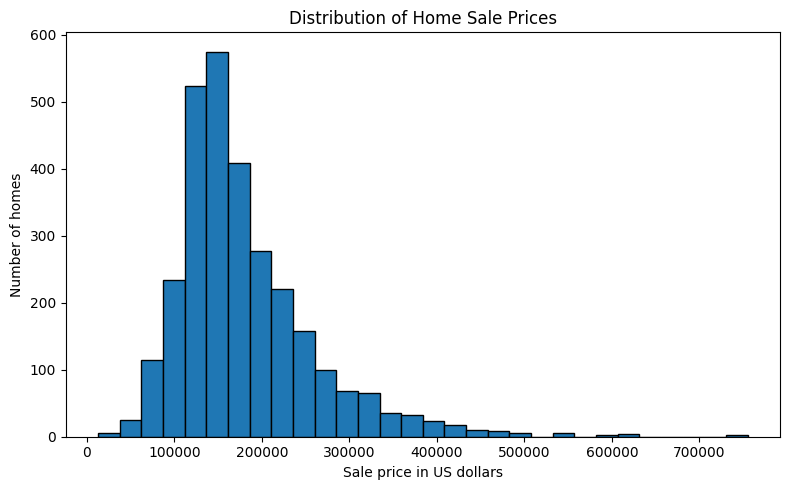

In [42]:
plt.figure(figsize=(8, 5))
plt.hist(homes["SalePrice"], bins=30, edgecolor="black")
plt.title("Distribution of Home Sale Prices")
plt.xlabel("Sale price in US dollars")
plt.ylabel("Number of homes")
plt.tight_layout()
plt.show()

In [43]:
homes.columns = (
    homes.columns
    .str.lower()
    .str.replace(r"[^a-z0-9]", "", regex=True)
)

possible_names = {
    "saleprice": ["saleprice"],
    "area": ["grlivarea", "abvgrdlivarea"],
    "neighborhood": ["neighborhood"],
    "propertytype": ["bldgtype"],
    "year": ["yrsold"],
    "month": ["mosold"]
}

found_columns = {}

for standard_name, choices in possible_names.items():
    for name in choices:
        if name in homes.columns:
            found_columns[standard_name] = name
            break

print("Columns matched:", found_columns)

required = ["saleprice", "area", "neighborhood", "propertytype", "year", "month"]
missing = [name for name in required if name not in found_columns]

if missing:
    print("Could not find these required fields:", missing)
    print("Check the printed column names and adjust possible_names.")
else:
    print("All required fields were found.")

Columns matched: {'saleprice': 'saleprice', 'neighborhood': 'neighborhood'}
Could not find these required fields: ['area', 'propertytype', 'year', 'month']
Check the printed column names and adjust possible_names.
